# EDA and Data Preprocessing
**AI-Powered Stock Market Prediction**

## 1. Setup

In [85]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.preprocessing import StandardScaler
from statsmodels.graphics.tsaplots import plot_pacf       
from statsmodels.stats.diagnostic import acorr_ljungbox   
pd.set_option("display.max_columns", None)                # show every column instead of "..."
pd.set_option("display.width", 200)
import warnings
warnings.filterwarnings("ignore")  # Ignore warnings for cleaner output

## 2. Load and clean the data

In [86]:
data_path = "dataset"
stock = ["AAPL", "NVDA", "JPM", "BHP", "CBA", "GMG"]

def check_data(data_path, csv_file):

    # Read the csv file into a dataframe
    file_path = f"{data_path}/{csv_file}.csv"
    df = pd.read_csv(file_path)

    # Convert date column to datetime format
    df['Date'] = pd.to_datetime(df['Date'], format= '%d %b %Y')

    # Sort from oldest to newest
    df = df.sort_values('Date').reset_index(drop=True)

    return df

raw_data = {s: check_data(data_path, s) for s in stock}
# Data quality summary for each stock
data_quality = pd.DataFrame([{
    "Stock": s,
    "Market": "US" if s in ['AAPL', 'NVDA', 'JPM'] else "AU",
    "Rows": len(df),
    "Start": df['Date'].min().date(),
    "End": df['Date'].max().date(),
    "Missing values": df.isnull().sum().sum(),
    "Duplicate rows": df.duplicated().sum(),
    "Duplicate dates": df.duplicated(subset=['Date']).sum(),
    "Zero volume days": (df['Volume'] == 0).sum()}
    for s, df in raw_data.items()])

data_quality


,Stock,Market,Rows,Start,End,Missing values,Duplicate rows,Duplicate dates,Zero volume days
0,AAPL,US,2010,2018-01-02,2025-12-30,0,0,0,0
1,NVDA,US,2010,2018-01-02,2025-12-30,0,0,0,0
2,JPM,US,2010,2018-01-02,2025-12-30,0,0,0,0
3,BHP,AU,2024,2018-01-02,2025-12-30,0,0,0,0
4,CBA,AU,2024,2018-01-02,2025-12-30,0,0,0,0
5,GMG,AU,2024,2018-01-02,2025-12-30,0,0,0,1


One non-trading observation was identified for **GMG on 19/2/25** (zero volume, with Open, High, Low, and Close equal to the previous close), consistent with a trading halt. This placeholder row was removed, as it would otherwise introduce an artificial 0% return and extreme values in the volume-change feature. The following day's return is therefore measured against the 18 Feburary close, preserving the true price movement.

In [87]:
# Clean the data
cleaned_data = {}

for s, df in raw_data.items():
    # Remove rows with zero volume
    non_trading = (df['Volume'] == 0) & (df['High'] == df['Low'])
    if non_trading.sum() > 0:
        print(f"{s}: {non_trading.sum()} non-trading day(s) removed")
    df = df[~non_trading]

    # Use date as the index (needed for the walk-forward steps)
    cleaned_data[s] = df.set_index('Date')
print(cleaned_data)
# Check again after cleaning
clean_data = pd.DataFrame([{
    "Stock": s,
    "Rows": len(df),
    "Missing values": df.isnull().sum().sum(),
    "Duplicate rows": df.reset_index().duplicated().sum(),
    "Duplicate dates": df.index.duplicated().sum(),
    "Zero volume days": (df['Volume'] == 0).sum()}
    for s, df in cleaned_data.items()
])

clean_data

GMG: 1 non-trading day(s) removed
{'AAPL':               Open    High     Low   Close  Adj Close     Volume
Date                                                            
2018-01-02   42.54   43.08   42.31   43.06      40.23  102223600
2018-01-03   43.13   43.64   42.99   43.06      40.23  118071600
2018-01-04   43.13   43.37   43.02   43.26      40.41   89738400
2018-01-05   43.36   43.84   43.26   43.75      40.87   94640000
2018-01-08   43.59   43.90   43.48   43.59      40.72   82271200
...            ...     ...     ...     ...        ...        ...
2025-12-23  270.84  272.50  269.56  272.36     271.62   29642000
2025-12-24  272.34  275.43  272.20  273.81     273.07   17910600
2025-12-26  274.16  275.37  272.86  273.40     272.66   21521800
2025-12-29  272.69  274.36  272.35  273.76     273.02   23715200
2025-12-30  272.81  274.08  272.28  273.08     272.34   22139600

[2010 rows x 6 columns], 'NVDA':               Open    High     Low   Close  Adj Close     Volume
Date         

,Stock,Rows,Missing values,Duplicate rows,Duplicate dates,Zero volume days
0,AAPL,2010,0,0,0,0
1,NVDA,2010,0,0,0,0
2,JPM,2010,0,0,0,0
3,BHP,2024,0,0,0,0
4,CBA,2024,0,0,0,0
5,GMG,2023,0,0,0,0


## 3. Walk-forward folds

**Walk-forward Validation** is a method for evaluating a model by simulating real-world forecasting. The model is trained using only data available prior to the forecast point, then advances incrementally over time. 
In this project, the team uses a 12-fold cross-validation approach using an expanding window. The first fold trains on data from January 2018 through December 2022 and testing on the first quarter of 2023. After each fold, the tested quarter is added to the training set for the subsequent fold, continuing until the 12th fold, which tests the fourth quarter of 2025.

**Why walk-forward validation with expanding window?**

+ A static split relies on a single testing period, making results highly dependent on whether the market is stable or volatile during that time. Financial data constantly changes, therefore, the walk-forward method addresses this by evaluating the model across diverse market phases. Furthermore, by utilizing only historical information within each fold, the method prevents future data leakage, ensuring the results accurately reflect the model's predictive capability.
+ The team chooses the expanding window approach because:
    The rolling window approach maintains a fixed training duration, while LSTM and CNN-LSTM models require substantial data, and discarding older data would reduce the number of training samples

In [88]:
# Build the list of 12 test quarters
test_quarters = pd.period_range(start='2023Q1', end='2025Q4', freq='Q')
folds = [(k+1, q.start_time, q.end_time) for k, q in enumerate(test_quarters)]

# Display the folds, using AAPL as an example
df = cleaned_data['AAPL']
fold_table = pd.DataFrame([{
    "Fold": k,
    "Training period": f"Jan 2018 - {(start - pd.Timedelta(days=1)):%b %Y}",
    "Test period": f"{start:%b %Y} - {end:%b %Y}",
    "Training days": (df.index < start).sum(),
    "Test days": ((df.index >= start) & (df.index <= end)).sum()
} for k, start, end in folds])

fold_table

,Fold,Training period,Test period,Training days,Test days
0,1,Jan 2018 - Dec 2022,Jan 2023 - Mar 2023,1259,62
1,2,Jan 2018 - Mar 2023,Apr 2023 - Jun 2023,1321,62
2,3,Jan 2018 - Jun 2023,Jul 2023 - Sep 2023,1383,63
3,4,Jan 2018 - Sep 2023,Oct 2023 - Dec 2023,1446,63
4,5,Jan 2018 - Dec 2023,Jan 2024 - Mar 2024,1509,61
5,6,Jan 2018 - Mar 2024,Apr 2024 - Jun 2024,1570,63
6,7,Jan 2018 - Jun 2024,Jul 2024 - Sep 2024,1633,64
7,8,Jan 2018 - Sep 2024,Oct 2024 - Dec 2024,1697,64
8,9,Jan 2018 - Dec 2024,Jan 2025 - Mar 2025,1761,60
9,10,Jan 2018 - Mar 2025,Apr 2025 - Jun 2025,1821,62


## 4. EDA

### 4.1 Closing prices

The shaded area is the walk-forward test period (2023-2025). Everything before it is the initial training data.

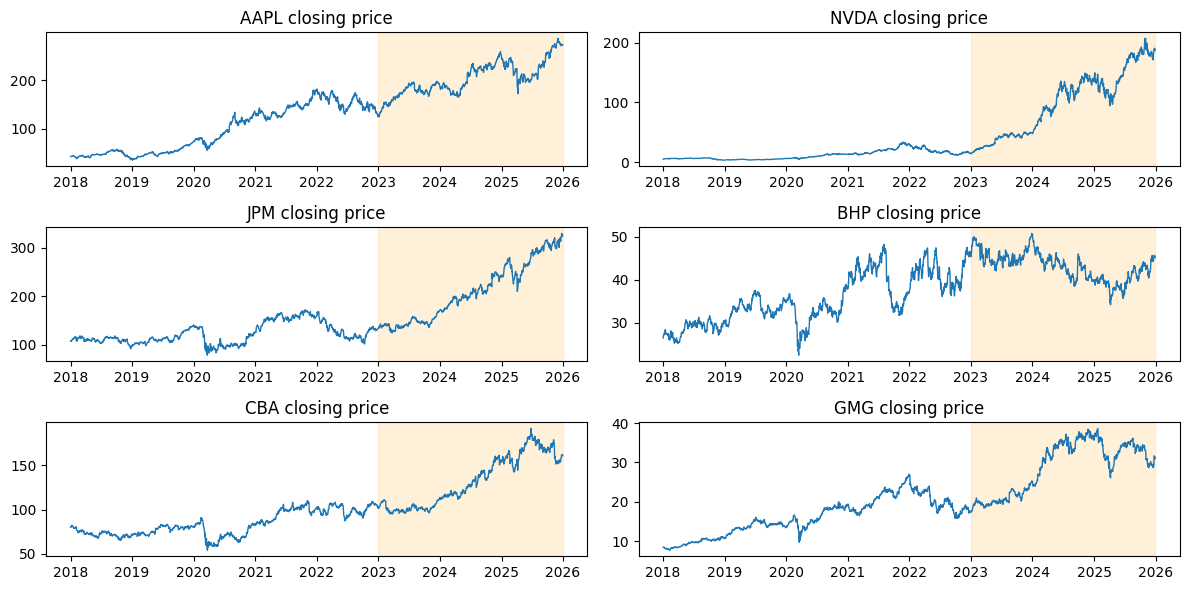

In [89]:
fig, axes = plt.subplots(3, 2,figsize=(12,6))
for ax, (name, df) in zip(axes.flatten(), cleaned_data.items()):
    ax.plot(df.index, df['Close'], linewidth=1)
    ax.axvspan(pd.Timestamp('2023-01-01'), pd.Timestamp('2025-12-31'), color='orange', alpha=0.15)
    ax.set_title(f"{name} closing price")
plt.tight_layout()
plt.show()

The figure above shows the daily closing prices of the six stocks from 2018 to 2025, with the walk-forward test period (2023-2025) shaded. All six series display clear trends rather than a stable mean, and common market shocks are visible across both markets, notably the COVID-19 crash in March 2020 and the sell-off in April 2025. Importantly, the test period differs markedly from the training period for several stocks: NVDA, JPM, CBA and AAPL reach price levels well above their 2018-2022 range, with NVDA rising roughly tenfold, whereas BHP remains within its historical range. This non-stationary means that models trained on raw price levels must extrapolate beyond the range obsered in training, which motivates modelling log returns rather than prices, and supports the use of walk-forwawrd validation to evaluate performance across changing market conditions.

### 4.2 Target Variable Analysis: Price Range and Log Returns

**Why we do not model raw prices?**

**"Close"** is the target variable. In the previous trial, LSTM and CNN-LSTM models were trained directly on price data, which was normalized to the [0,1] range using a Min-Max scaler fitted to the training set. This approach has a fundamental limitation: the scaler only learns the minimum and maximum values from the training period; consequently, if prices during the test period exceed the historical peak, the normalized values exceed 1. Since the models were never trained on this range, they were forced to extrapolate, often resulting in systematic prediction errors. This explains why the NVDA forecast curve flattened and JPM was consitenly under-predicted for the first model application, whereas BHP, whose test prices remained within the obsered range, yielded the best predictions. To verify this issue within the walk-forward framework, the team checks what share of the test quarter's prices is **higher than the highest price in that fold's training data**.

In [90]:
rows = []
for name, df in cleaned_data.items():
    for k, start, end in folds:
        train_max = df.loc[df.index < start, 'Close'].max()
        test_prices = df.loc[(df.index >= start) & (df.index <= end), 'Close']
        rows.append({
            "Stock": name,
            "Fold": k,
            "% test days above train max": 100 *(test_prices > train_max).mean()
        })
above_train_max = pd.DataFrame(rows).pivot(index = 'Stock', columns = 'Fold', values = '% test days above train max')
above_train_max.round(0)

Fold,1,2,3,4,5,6,7,8,9,10,11,12
Stock,,,,,,,,,,,,
AAPL,0.0,23.0,10.0,6.0,0.0,21.0,91.0,42.0,0.0,0.0,0.0,78.0
BHP,35.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
CBA,10.0,0.0,0.0,5.0,94.0,35.0,85.0,59.0,15.0,66.0,0.0,0.0
GMG,0.0,0.0,0.0,0.0,53.0,50.0,24.0,27.0,2.0,0.0,0.0,0.0
JPM,0.0,0.0,0.0,0.0,79.0,13.0,89.0,64.0,58.0,8.0,81.0,21.0
NVDA,0.0,40.0,65.0,14.0,93.0,41.0,0.0,67.0,2.0,6.0,97.0,43.0


The table above shows that this rate reached 97% for NVDA (Fold 11), 94% for CBA (Fold 5), 91% for AAPL (Fold 7), and 89% for JPM (Fold 7), whereas it was near zero for BHP. Therefore rather than forecasting prices, the models will be trained to predict next-day log returns. The predicted returns were then converted back to closing prices for evaluation, ensuring that the RMSE, MAE, and MAPE metrics will be calculated based on the original price scale. 

**Daily log returns and descriptive statistics**

**Log return** measures the change in a stock's closing price from the previous day to the current day, using the formula:

$$
r_t = \ln\left(\frac{\text{Close}_t}{\text{Close}_{t-1}}\right)
$$

where $\text{Close}_t$ is today's closing price, $\text{Close}_{t-1}$ is yesterday's closing price

With small changes, the log return is almost the same percentage of the typical change. For example, the price increases from 100USD to 102USD, $r_t = \ln(102/100) \approx 0,0198$, which is about +2%. Unlike the price, which gradually increases over time, the yield always fluctuates around 0 and is in a relatively stable range, regardless of what price the stock is at. We use logarithms instead of regular percentages for two reasons: log returns can compound over time (a 1% increase and then a 2% increase equals a total return of 3%), and it is symmetrical between price increases and decreases, making statistical calculations and modeling more accurate.

In [91]:
log_returns = {}

# Daily log returns for each stock: r_t = ln(Close_t / Close_{t-1})
for s, df in cleaned_data.items():
    #shift(1) = yesterday's closing price, dropna() removes the first row which is NaN
    log_returns[s] = np.log(df['Close'] / df['Close'].shift(1)).dropna() 

return_stats = pd.DataFrame([{
    "Stock": s,
    "Mean (%)": 100 * r.mean(),    # average daily return
    "Std (%)": 100 * r.std(),      # std of daily return
    "Annual volatility (%)": 100 * r.std() * np.sqrt(252), # 252 trading days in a year
    "Min (%)": 100 * r.min(),        # worst daily return   
    "Worst date": r.idxmin().date(), # date of worst daily return
    "Max (%)": 100 * r.max(),        # best daily return
    "Best date": r.idxmax().date(),  # date of best daily return
    "Skewness": r.skew(),             # skewness of daily returns 
    "Excess Kurtosis": r.kurtosis(),          # kurtosis of daily returns
    "Jarque-Bera p-value": stats.jarque_bera(r).pvalue
} for s, r in log_returns.items()])     
return_stats.round(3)

,Stock,Mean (%),Std (%),Annual volatility (%),Min (%),Worst date,Max (%),Best date,Skewness,Excess Kurtosis,Jarque-Bera p-value
0,AAPL,0.092,1.938,30.768,-13.771,2020-03-16,14.262,2025-04-09,-0.083,6.208,0.0
1,NVDA,0.181,3.229,51.254,-20.794,2018-11-16,21.802,2023-05-25,-0.189,4.708,0.0
2,JPM,0.055,1.831,29.065,-16.211,2020-03-16,16.562,2020-03-13,-0.089,13.056,0.0
3,BHP,0.026,1.713,27.198,-15.561,2020-03-09,11.282,2020-03-17,-0.461,6.040,0.0
4,CBA,0.035,1.435,22.785,-10.543,2020-03-16,12.453,2020-03-17,-0.310,10.293,0.0
5,GMG,0.064,1.772,28.127,-15.797,2020-03-19,16.499,2020-03-20,-0.407,12.303,0.0


The table above summurizes the characteristics of daily log returns for six stocks during the 2018-2025 period:
+ **Mean**: the average daily price change
+ **Standard deviation**: the typical percentage fluctuation of the price on an average day
+ **Annual volatility**: converts std to an annual figure (by multiplying by sqrt(252), as there are approxiamtely 252 trading days). This is the most common measure of risk in finance: the higher the figure, the more volatile the price movements and the harder they are to predict.
+ **Min and Max**: represent the days with the sharpest declines and increases, respectively. They help identify unusual market events and allow for data error checks.
+ **Skewness**: indicates whether the distribution is symmetrical. A negative value implies that sharp declines occur more frequently or are more severe than sharp gains
+ **Kurtosis** or excess kurtosis: it is zeo for a normal (bell-shaped) distribution. The higher the value above zero, the more the data exhibits days of extreme volatility-a phenomenon known as fat tails.
+ **Jarque-Bera p-value**: is the result of a test determining whether the data follows a normal distribution. If the p-value is less than 0.05, we conclude that the data is not normally distributed.


Based on the table:
+ The average returns for all six stocks are very close to zero (from 0.03% to 0.18% daily), indicating that returns do not exhibit te upward or downward trends seen in stocks prices.
+ NVDA is the riskies, with an annualized volatility of 51.3%, nearly double that of the other stocks, reflecting the characteristics of a high-growth technology stock. Coversely, CBA is the most stable (22.8%), consistent with its status as a major Australian Bank. AAPL, JPM, GMG, and BHP fall within the moderate range (27-31%). This implies that the model's forecast error for NVDA is likely to be higher than for the other stocs; this not due to model inadequacy but rather the inherently less predictable nature of the stock itself.
+ Minimum and maximum values reveal days of extreme volatility, such as NVDA dropping 20.8% and rising 21.8% in a single day. Most of the sharpest declines occurred in March 2020 during the outbreak of COVID-19 pandemic. These represents actual market events rather than data errors.
+ Negative skewness is observed across all six stocks indicating a market tendency to rise gradually but fall abruptly.
+ Excess kurtosis values for all stocks are significantly above zero (fat tails).
+ Normality test: The Jarque-Bera p-value is 0 for all six tickers, statistically confirming that the returns do not follow a normal distribution

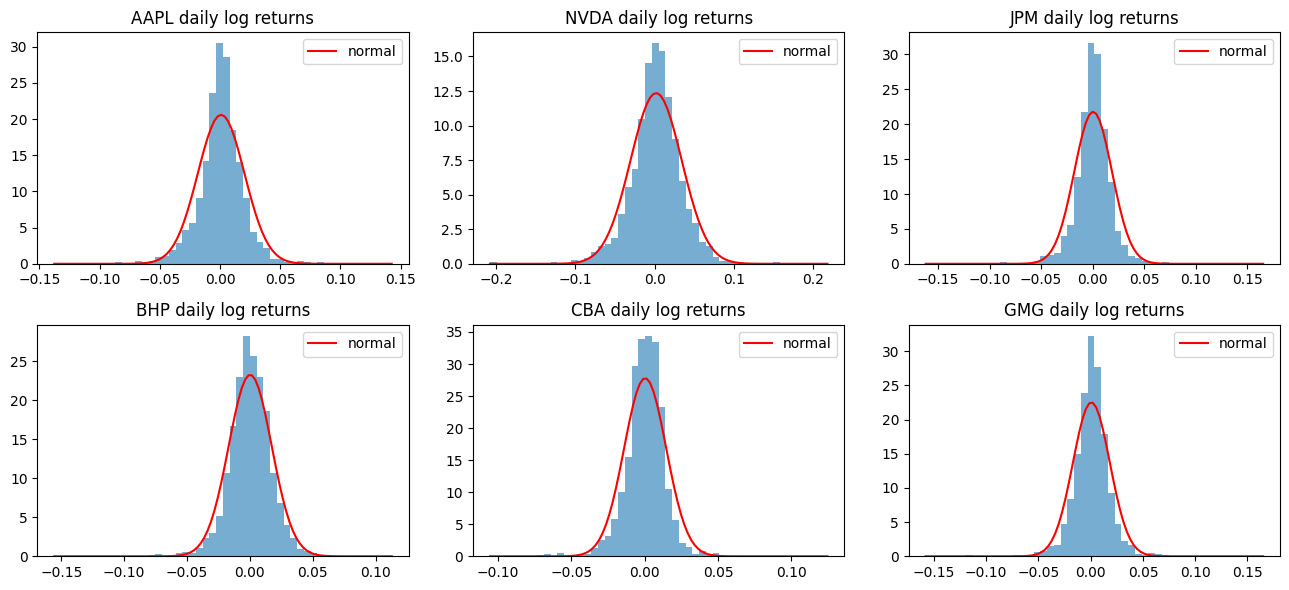

In [92]:
fig, axes = plt.subplots(2, 3, figsize=(13,6))
for ax, (name, r) in zip(axes.flatten(), log_returns.items()):
    ax.hist(r, bins=50, density=True, alpha=0.6)
    x = np.linspace(r.min(), r.max(), 100)
    ax.plot(x, stats.norm.pdf(x, loc=r.mean(), scale=r.std()), color='red', label='normal')
    ax.set_title(f"{name} daily log returns")
    ax.legend()
plt.tight_layout()
plt.show()

The firgure above again confirms that the distribution of all six stocks do not follow normal distribution. It could mean that markets are calm on most days but occasionally experience extreme shocks. Because such extreme observations can dominate a squared-error loss, winsorsation is considered during preprocessing, and the Diebold-Mariano test, which does not assume normality, is also used for model comparison.

### 4.3 Stationarity (ADF test)

**A stationary series** do not change over time, it consistently fluctuates around a fixed mean with relatively stable volatility. **Augmented Dickey-Fuller** (ADF) test is a statistical test that answers the question whether this data series is stationary.
**Why ADF  test is used?**
+ All forecasting models rely on the assumption that patterns learned from the past remain valid in the future. This assumption holds true only when the data is stationary.
+ ARIMA models function correctly only with stationary data. If the data is non-stationary, differencing must be applied to transform it into a stationary series. The number of differencing operations performed corresponds to the parameter d in ARIMA(p,d,q). The ADF test assists in determining d.
+ The ADF test provides formal statistical evidence to support th decision to forecast returns rather than raw prices.


Our null hypothesis:
+ $H_0$: The series is non-stationary
+ $H_1$: The series is stationary

In [93]:
adf_results = pd.DataFrame([{
    "Stock": s,
    "ADF p-value log price": adfuller(np.log(df['Close']))[1], #[1] = p-value
    "ADF p-value log returns": adfuller(log_returns[s])[1]
} for s, df in cleaned_data.items()])

adf_results["Price stationary?"] = adf_results["ADF p-value log price"] < 0.05
adf_results["Returns stationary?"] = adf_results["ADF p-value log returns"] < 0.05
adf_results.round(2)

,Stock,ADF p-value log price,ADF p-value log returns,Price stationary?,Returns stationary?
0,AAPL,0.75,0.0,False,True
1,NVDA,0.98,0.0,False,True
2,JPM,0.96,0.0,False,True
3,BHP,0.09,0.0,False,True
4,CBA,0.88,0.0,False,True
5,GMG,0.38,0.0,False,True


**ADF results.** For all six stocks the p-value for the log price is above 0.05 (0.09 to 0.98), so H0 cannot be rejected: log prices are non-stationary. BHP is the closest to the threshold (p = 0.09), consistent with its price staying within its historical range rather than trending strongly upward (Section 4.1), but it still fails the test at the 5% level. For log returns the p-value is 0.00 (rounded) for every stock, so returns are stationary. This is the formal evidence behind two decisions: the deep-learning models predict returns rather than prices, and ARIMA uses d = 1 (confirmed fold by fold in Section 5.4).

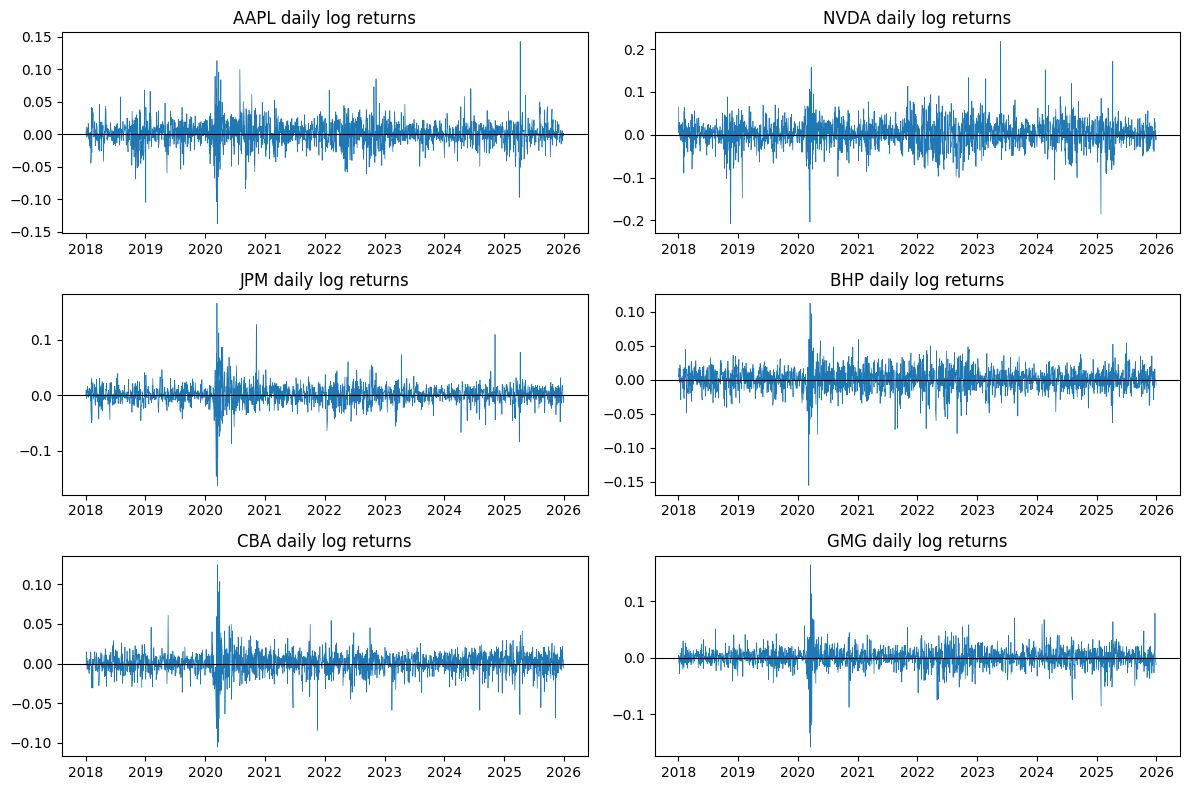

In [94]:
# Plot the returns over time (compare with the price chart: no trend, moves around 0)
fig, axes = plt.subplots(3, 2, figsize=(12, 8))
for ax, (s, r) in zip(axes.flatten(), log_returns.items()):
    ax.plot(r.index, r, linewidth=0.5)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(f"{s} daily log returns")
plt.tight_layout()
plt.show()

### 4.4 Autocorrelation

**Autocorrelation** measures the extent to which today's value resembles (or is related to) its own past values. It answers the question: "If we know what happened yesterday, can we predict what will happen today?". The autocorrelation coefficient ranges from -1 to +1:
+ +1: if yesterday saw an increase, today likely sees an increase too.
+ 0: yesterday offers no predictive power for today.
+ -1: if yesterday saw an increase, today likely sees a decrease.


**Why autocorrelation is used?"**
+ Understanding the difficulty of the problem and the need for a naive baseline.
+ Selecting parameters for ARIMA. ARIMA(p,d,q) involves two parameters selected based on specific plots: p based on the PACF plot; q based on the ACF plot
+ Justification for using LSTM: Given than simple (linear) autocorrelation is weak, the question arises as to whether there are complex (non-linear) patterns that the ACF fails to detect. LSTM and CNN-LSTM models are desinged to identify such patterns within 60-day sequence. This can answer the quesion: can neural networks uncover information that ARIMA misses?

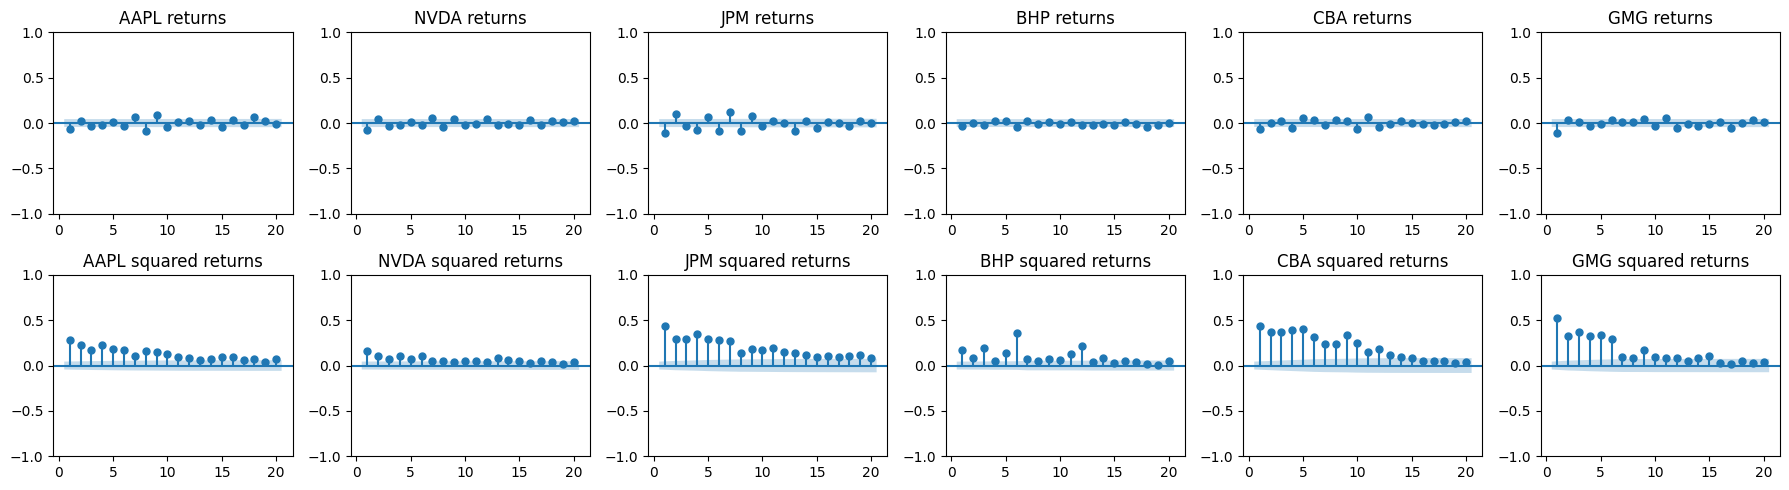

In [95]:
fig, axes = plt.subplots(2, 6, figsize=(18, 5))
for i, (s, r) in enumerate(log_returns.items()):
    plot_acf(r, lags=20, zero = False, ax=axes[0, i], title=f"{s} returns")
    plot_acf(r**2, lags=20, zero = False, ax=axes[1,i], title=f"{s} squared returns")
plt.tight_layout()
plt.show()

The ACF plots reveal very weak autocorrelation in daily log returns across all six stocks: most coefficients are close to zero, with only JPM and GMG exhibiting a small negative coefficient. This indicates that the direction of price movements is virually unpredictable based on past returns, making the naive forecase a difficult benchmark to beat. In constrast, the autocorrelation of squared returns is clearly positive and decays with the lag, particularly for CBA, JPM, GMG, and AAPL, reflecting the phenomenon of volatility clusterng, where periods of high volatility tend to persist. Consequently, the difficulty of forecasting varies over time, reinforcing the need to evaluate models using a multi-fold walk-forward approach rather than a single test period.

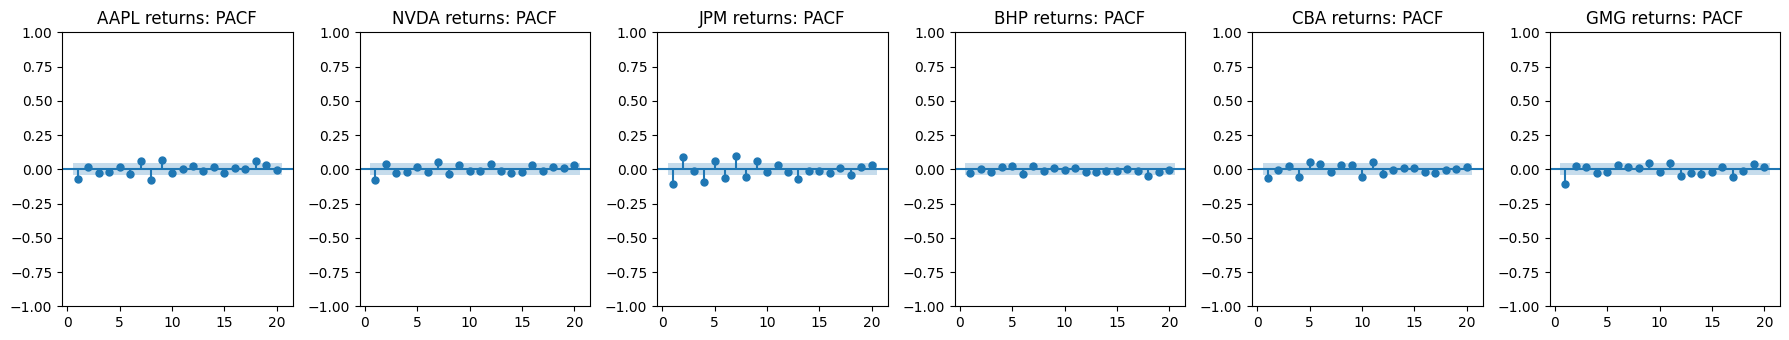

In [136]:
# The PACF shows the direct link between today and lag k after removing the shorter lags.
# It is used to choose the AR order p of ARIMA (the ACF above is used for the MA order q).
fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
for ax, (s, r) in zip(axes, log_returns.items()):
    plot_pacf(r, lags=20, zero=False, method="ywm", ax=ax, title=f"{s} returns: PACF")
plt.tight_layout()
plt.show()

In [156]:
# H0: no autocorrelation up to lag 10. p < 0.05 means autocorrelation is present.
# Turns the visual reading of the ACF plots into a formal test.
# The test is repeated without 2020 to see how much of the result comes from the COVID period.
lb_rows = []
for s, r in log_returns.items():
    r_no_2020 = r[r.index.year != 2020]
    lb_rows.append({
        "Stock": s,
        "LB p-value: returns (lag 10)": acorr_ljungbox(r, lags=[10])["lb_pvalue"].iloc[0],
        "LB p-value: returns, excluding 2020": acorr_ljungbox(r_no_2020, lags=[10])["lb_pvalue"].iloc[0],
        "LB p-value: squared returns (lag 10)": acorr_ljungbox(r ** 2, lags=[10])["lb_pvalue"].iloc[0]})
ljung_box = pd.DataFrame(lb_rows)
ljung_box.round(4)

,Stock,LB p-value: returns (lag 10),"LB p-value: returns, excluding 2020",LB p-value: squared returns (lag 10)
0,AAPL,0.0000,0.5678,0.0
1,NVDA,0.0000,0.5724,0.0
2,JPM,0.0000,0.2311,0.0
3,BHP,0.5149,0.4447,0.0
4,CBA,0.0000,0.6798,0.0
5,GMG,0.0001,0.0209,0.0


**PACF.** Most partial autocorrelations lie inside the 95% band. The only consistent pattern is a small negative coefficient at lag 1 for five of the six stocks (between −0.06 and −0.11; BHP has none): on average, a rise today is followed by a very slight fall tomorrow. The PACF therefore points to a small AR order (p = 0 or 1) for ARIMA. As planned, the final p and q will be chosen by AIC within each fold.

**Ljung-Box test.** Over the full 2018–2025 sample, the test rejects "no autocorrelation" in returns for every stock except BHP (p = 0.51). This looks stronger than the ACF plots suggest, because the test adds up ten small coefficients over about 2,000 days, and much of the effect comes from the COVID period: with 2020 excluded, only GMG remains significant (p = 0.02). The autocorrelation in returns is therefore weak and not stable over time, which is why the naive forecast is a hard benchmark to beat. For squared returns, p = 0.00 for all six stocks, formally confirming the volatility clustering seen in the plots above.

### 4.5 Volatility over time

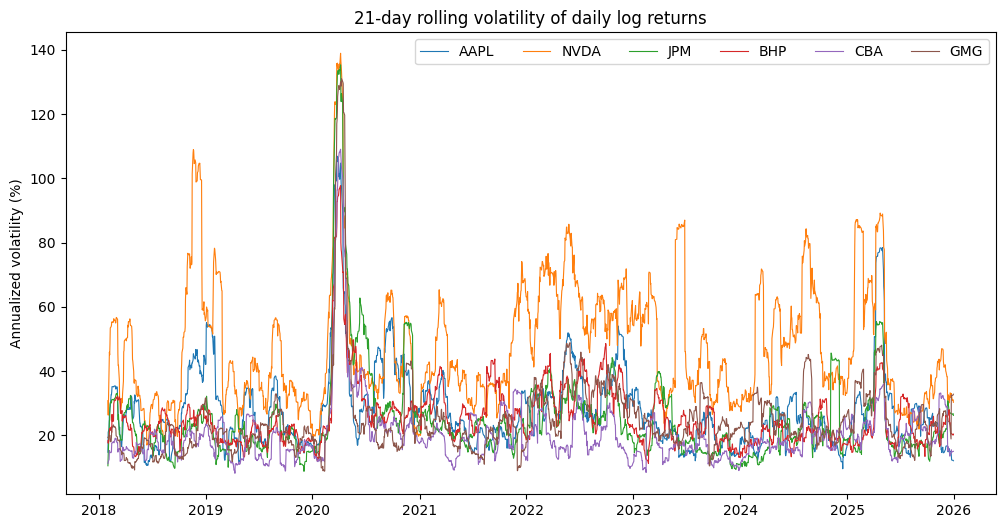

In [157]:
plt.figure(figsize=(12, 6))
for name, r in log_returns.items():
    rolling_vol = r.rolling(window=21).std() * np.sqrt(252) * 100 # 21 trading days ~ 1 month, annualized volatility in %
    plt.plot(rolling_vol, linewidth=0.8, label=name)
plt.ylabel("Annualized volatility (%)")
plt.title("21-day rolling volatility of daily log returns")
plt.legend(ncol=6)
plt.show()

The figure shows the 21-day rolling annualised volatility of each sotck. Volatility is clearly time-varying, with pronounced spikes during the COVID-19 creash in 2020 and 2025, followed by gradual decline, consistent with the volatitily clustering observed in the squared-return autocorrelations. As a result, some walk-forward test quarters are inherently more difficult to forecast than others, which motivates reporting performance as the mean and std across all 12 folds.

### 4.6 Correlation between stocks

Correlation measures the extent to which two stocks move together. 

**Why correlation?**
+ Comparing between the US and Australian markets: Correlation analysis reveals whether stocks within the same market exhibit similar volatility; whether stocks across the two markets are interrelated. 
+ Supporting SHAP analysis: Highly correlated stocks may exhibit similar behvior, potentially leading to more similar SHAP results.


In general, the correlation analysis does not alter the model construction process; rather, it serves as contextual analysis to aid in understanding and interpreting the results.

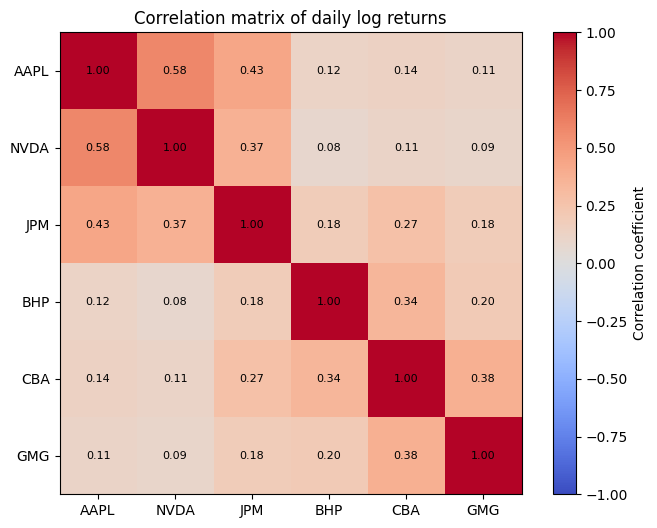

In [158]:
returns_table = pd.DataFrame(log_returns).dropna()
correlation_matrix = returns_table.corr()
plt.figure(figsize=(8, 6))
plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation coefficient')
plt.xticks(range(6), correlation_matrix.columns)
plt.yticks(range(6), correlation_matrix.index)
for i in range(6):
    for j in range(6):
        plt.text(j, i, f"{correlation_matrix.iloc[i, j]:.2f}", ha='center', va='center', fontsize=8)
plt.title("Correlation matrix of daily log returns")
plt.show()

The figure shows that all stock are positively correlated, although only at low to moderate levels (0.08-0.58). Correlations within each market are noticeably stronger than those across markets: the two US technology stocks, AAPL and NVDA, display the highest correlation (0.58), whereas US-Australian pairs range only 0.08-0.27. JPM and CBA (banks) form the most correlated cross-market pair (0.27), while NVDA and BHP (tech vs mining) are the least correlated (0.08). These results ndicate that each market has distinct return dynamics, which supports evaluating the models separately across both markets.

In [175]:
# The ASX closes before New York opens, so news from US day t-1 reaches Australia on day t.
# Pair each Australian trading day with the most recent US trading day BEFORE it.
us_stocks, au_stocks = ["AAPL", "NVDA", "JPM"], ["BHP", "CBA", "GMG"]
au_table = pd.DataFrame({s: log_returns[s] for s in au_stocks}).dropna()
us_table = pd.DataFrame({s: log_returns[s] for s in us_stocks}).dropna()

us_previous = pd.merge_asof(au_table.index.to_frame(name="Date", index=False),
                            us_table.rename_axis("Date").reset_index(),
                            on="Date", allow_exact_matches=False).set_index("Date")

lag_rows = []
for u in us_stocks:
    for a in au_stocks:
        lag_rows.append({"US stock": u, "AU stock": a,
                         "Same-day correlation": correlation_matrix.loc[u, a],
                         "US previous day -> AU day": au_table[a].corr(us_previous[u])})
lagged_corr = pd.DataFrame(lag_rows)
lagged_corr.round(2)

,US stock,AU stock,Same-day correlation,US previous day -> AU day
0,AAPL,BHP,0.12,0.17
1,AAPL,CBA,0.14,0.08
2,AAPL,GMG,0.11,0.19
3,NVDA,BHP,0.08,0.13
4,NVDA,CBA,0.11,0.08
5,NVDA,GMG,0.09,0.22
6,JPM,BHP,0.18,0.18
7,JPM,CBA,0.27,0.14
8,JPM,GMG,0.18,0.08


**Effect of the time-zone gap.** The ASX trading day ends before the US trading day starts, so a same-date correlation pairs an Australian day with a US day that happens *after* it. Pairing each Australian day with the *previous* US day gives a different picture. For BHP and GMG the correlation with the previous US day is higher than the same-day figure (e.g. NVDA → GMG 0.22 vs 0.09, AAPL → GMG 0.19 vs 0.11), while for CBA it is lower (JPM → CBA 0.14 vs 0.27). Cross-market links are therefore spread over two consecutive days, and the same-day matrix above understates them for BHP and GMG. They remain weak either way (at most 0.27), so the conclusion that the two markets have distinct return dynamics still holds. The models use no cross-stock inputs, so this does not change the preprocessing; it is context for the cross-market comparison.

### 4.7 Outliers

In [176]:
outliers = []
for s, df in cleaned_data.items():
    # Old method: IQR method to detect outliers
    q1, q3 = df['Close'].quantile([0.25, 0.75])
    upper_bound = q3 + 1.5 * (q3 - q1)
    flagged_outliers = df[df['Close'] > upper_bound]

    # New method: 1st/99th percentile on returns
    r = log_returns[s]
    r_train = r[r.index < '2023-01-01'] # Use data before the test period for training
    low, high = r_train.quantile([0.01, 0.99])

    outliers.append({
        "Stock": s,
        "Price IQR outliers": len(flagged_outliers),
        "First flagged date": flagged_outliers.index.min().date() if len(flagged_outliers) > 0 else None,
        "Return outliers":((r_train < low) | (r_train > high)).sum()})

pd.DataFrame(outliers)

,Stock,Price IQR outliers,First flagged date,Return outliers
0,AAPL,0,None,26
1,NVDA,347,2024-05-29,26
2,JPM,191,2025-01-17,26
3,BHP,0,None,26
4,CBA,143,2025-02-12,26
5,GMG,0,None,26


The percentile approach affects only a small, fixed share of observations (about 2%), the most extreme days, rather than hundreds of consecutive days. Below we draw two graphs, using NVDA as an example, to clearly show the difference when removing outliers using old and new method.

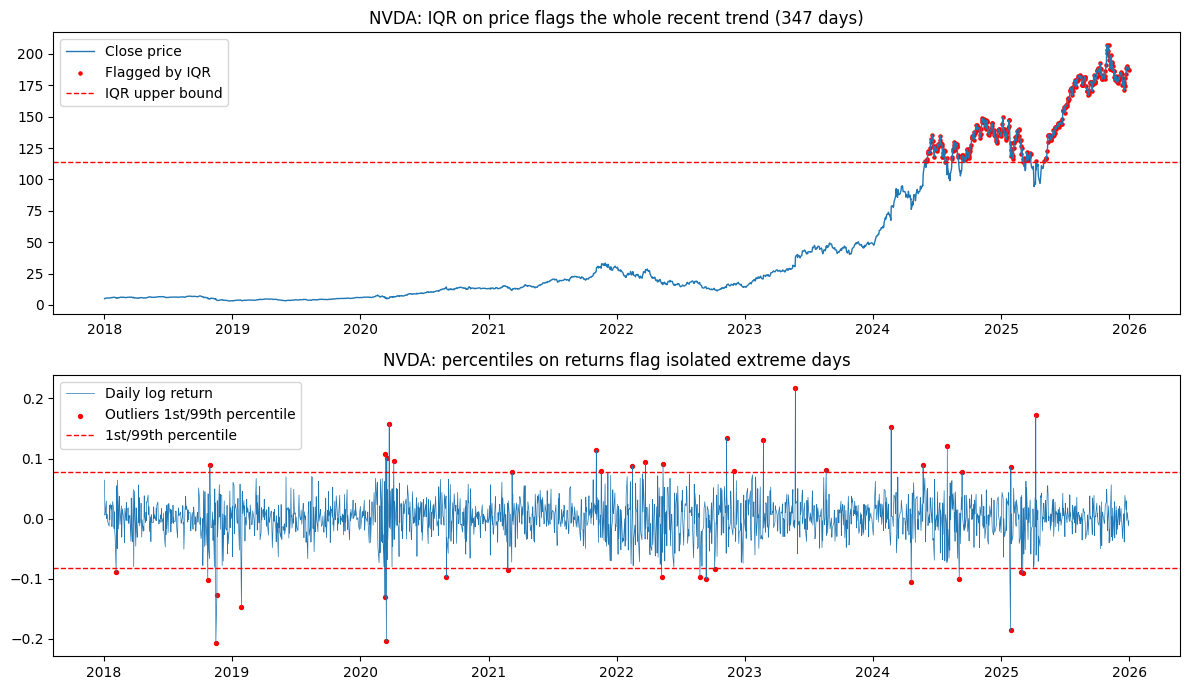

In [177]:
s = 'NVDA'
df = cleaned_data[s]
r = log_returns[s]
fig, axes = plt.subplots(2,1, figsize = (12,7))

# Old method
q1,q3 = df['Close'].quantile([0.25,0.75])
upper_bound = q3 + 1.5 * (q3 - q1)
flagged_outliers = df['Close'] > upper_bound
axes[0].plot(df.index, df['Close'], linewidth =1, label = 'Close price')
axes[0].scatter(df.index[flagged_outliers], df['Close'][flagged_outliers], color='red', s=5, label ='Flagged by IQR')
axes[0].axhline(upper_bound, color='red', linestyle='--', linewidth = '1', label = 'IQR upper bound')
axes[0].set_title(f"{s}: IQR on price flags the whole recent trend ({flagged_outliers.sum()} days)")
axes[0].legend()

# New method
r_train = r[r.index < '2023-01-01']
low, high = r_train.quantile([0.01, 0.99])
outside = (r<low) | (r>high)
axes[1].plot(r.index, r, linewidth=0.5, label = 'Daily log return')
axes[1].scatter(r.index[outside], r[outside], color='red', s=8, label='Outliers 1st/99th percentile')
axes[1].axhline(low, color='red', linestyle='--', linewidth =1)
axes[1].axhline(high, color='red', linestyle='--', linewidth =1, label = '1st/99th percentile')
axes[1].set_title(f"{s}: percentiles on returns flag isolated extreme days")
axes[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
# test-period returns beyond the training limits
# For each fold, the 1st/99th percentile limits come from returns BEFORE the test quarter.
# Count how many test-quarter returns fall outside them: these are the days winsorisation
# would clip in the model inputs. Unlike the fixed 2% above, this number can vary.
rows = []
for s, r in log_returns.items():
    for k, start, end in folds:
        r_train = r[r.index < start]
        low, high = r_train.quantile([0.01, 0.99])
        r_test = r[(r.index >= start) & (r.index <= end)]
        rows.append({"Stock": s, "Fold": k,
                     "% test days outside limits": 100 * ((r_test < low) | (r_test > high)).mean()})
test_outside = pd.DataFrame(rows)
test_outside_summary = (test_outside.groupby("Stock")["% test days outside limits"]
                        .agg(["mean", "max"]).round(1).reindex(stock))
test_outside_summary["Fold with max"] = (test_outside.loc[test_outside.groupby("Stock")["% test days outside limits"].idxmax()]
                                         .set_index("Stock")["Fold"])
test_outside_summary

,mean,max,Fold with max
Stock,,,
AAPL,0.9,8.1,10
NVDA,2.0,6.7,9
JPM,1.1,4.8,10
BHP,0.5,3.3,10
CBA,0.9,3.3,10
GMG,1.9,4.9,9



**Test-period returns outside the training limits.** The "Return outliers" column above is 26 for every stock by construction: a 1st/99th percentile cut-off always flags about 2% of the rows it was computed on. The more informative question is how often the *test* quarters go beyond limits learned from the past. On average this happens on 0.5% (BHP) to 2.0% (NVDA) of test days, roughly one day per quarter, so winsorisation changes very few test inputs. The exceptions are in 2025: AAPL reaches 8.1% in fold 10 (Apr–Jun 2025, which contains the April 2025 sell-off) and NVDA 6.7% in fold 9 (Jan–Mar 2025). These are the quarters where clipped inputs differ most from the raw data, so they are worth checking when raw and winsorised results are compared.

### 4.8 Close vs Adj Close

The dataset has two closing prices. `Close` is adjusted for stock splits only; `Adj Close` is also adjusted for dividends. On an ex-dividend day the share price drops by roughly the dividend paid, so a return computed from `Close` shows a fall that is not a market movement. This section measures how large that effect is for each stock.

In [ ]:
# ---- Close vs Adj Close ----
# Close is adjusted for stock splits only. Adj Close is also adjusted for dividends.
# On an ex-dividend day the Close drops by roughly the dividend, which shows up as a
# negative return that the OHLCV inputs cannot explain.
adj_rows = []
for s, df in cleaned_data.items():
    r_close = np.log(df["Close"] / df["Close"].shift(1)).dropna()
    r_adj = np.log(df["Adj Close"] / df["Adj Close"].shift(1)).dropna()
    gap = 100 * (r_adj - r_close)          # % points; positive on ex-dividend days
    adj_rows.append({
        "Stock": s,
        "Days with gap > 0.5%": (gap > 0.5).sum(),
        "Largest gap (%)": gap.max(),
        "Largest gap date": gap.idxmax().date(),
        "Total return 2018-25, Close (%)": 100 * (np.exp(r_close.sum()) - 1),
        "Total return 2018-25, Adj Close (%)": 100 * (np.exp(r_adj.sum()) - 1)})
adj_table = pd.DataFrame(adj_rows)
adj_table.round(2)

,Stock,Days with gap > 0.5%,Largest gap (%),Largest gap date,"Total return 2018-25, Close (%)","Total return 2018-25, Adj Close (%)"
0,AAPL,0,0.45,2019-02-08,534.18,576.96
1,NVDA,0,0.30,2019-01-09,3665.86,3707.11
2,JPM,30,1.03,2020-04-03,199.60,272.88
3,BHP,17,7.06,2021-09-02,70.64,206.93
4,CBA,16,3.11,2018-08-15,101.06,181.66
5,GMG,12,1.40,2018-12-28,266.71,316.22


> *Newly added by Claude*

For AAPL and NVDA the difference is negligible (no day above 0.5%). For JPM and the three Australian stocks it is large: over 2018–2025 BHP's `Close` rose 70.6% but its dividend-adjusted return was 206.9%, and CBA's 101.1% vs 181.7%. BHP has 17 days on which the `Close`-based return understates the true return by more than 0.5 percentage points, the largest being 7.06% on 2021-09-02.

**Decision:** the target remains `Close`, because RQ1 asks about the next-day closing price and the models are evaluated against actual closing prices. The ex-dividend drops are recorded as a limitation: the models cannot anticipate them from OHLCV inputs, which will slightly raise errors for BHP, CBA, GMG and JPM on those days. A sensitivity check that rebuilds the return features from `Adj Close` could be run if time allows.

## 5. Preprocessing

### 5.1 Features

**Changes from the Assessment 2 plan.** The preprocessing below differs from the plan in Assessment 2. The changes and reasons are:

| Assessment 2 plan | Now | Reason |
|---|---|---|
| Target: next-day closing price | Target: next-day log return, converted back to a price for evaluation | Test prices often exceed the training maximum (up to 97% of a quarter for NVDA, Section 4.2), forcing the models to extrapolate. Recommended in the Assessment 2 feedback. |
| Min-Max scaling to [0, 1] | `StandardScaler` (mean 0, std 1) | The return features are centred on zero and roughly symmetric, which standardisation preserves. Both scalers would be fitted per fold on training rows only; the change is about the shape of the inputs, not leakage. |
| Winsorisation at the 5th/95th percentile of prices | Winsorisation at the 1st/99th percentile of returns | Feedback: capping a trending price series clips the test period. On returns, 5th/95th would alter about 10% of all days, most of them ordinary trading days; 1st/99th limits only the most extreme ~2% (Section 4.7). |
| IQR outlier detection on prices | Percentile limits on returns | IQR on prices flags the recent upward trend, not genuine outliers (Section 4.7). |
| Static 70/15/15 split | 12-fold expanding-window walk-forward; last 15% of each fold's pre-test data is validation | Evaluates the models over 12 different market periods (Section 3). |
| No baseline | Naive persistence baseline | Recommended in the Assessment 2 feedback (Section 5.5). |
| Compare raw vs winsorised data | `winsor=None` option in `preprocess_fold` | The comparison needs trained models, so it will be run in the modelling notebooks. |

EDA reveals that stock prices tend to exhibit upward, non-stationary trend over time. Furthermore, prices during the test period often fall outside the range observed during the training phase. Using raw Open, High, Low, Close and Volume (OHLCV) data as model inputs would force the model to exptrapolate, increasing the risk of inaccurate predictions. To address this, all five OHLCV variables are transformed into variations relative to the previous day's closing price

| Feature | Formula | Meaning |
|---|---|---|
| Open | $ln\left(\frac{Open_t}{Close_{t-1}}\right)$ | overnight gap 
| High | $ln\left(\frac{High_t}{Close_{t-1}}\right)$ | how far the price rose during the day 
| Low | $ln\left(\frac{Low_t}{Close_{t-1}}\right)$ | how far the price fell during the day 
| Close | $ln\left(\frac{Close_t}{Close_{t-1}}\right)$ | daily log return 
| Volume | $ln(Volume_t) - ln(Volume_{t-1})$ | change in trading volume 

**Target variable** will be turned back to price. A predicted return is turned back into a price with: ***predicted price = today's close x exp(predicted return)***

In [180]:
def transform_features(df):
    # Turn raw OHLCV prices into the five return-based features
    prev_close = df['Close'].shift(1)   # yesterday's close
    var = pd.DataFrame(index=df.index)
    var['Open'] = np.log(df['Open']/prev_close)
    var['High'] = np.log(df['High']/prev_close)
    var['Low'] = np.log(df['Low']/prev_close)
    var['Close'] = np.log(df['Close']/prev_close)
    var['Volume'] = np.log(df['Volume'] + 1).diff()   # +1 avoids log(0), first row has no yesterday
    return var.dropna()
# Use AAPL as an example
transform_features(cleaned_data['AAPL']).head()

,Open,High,Low,Close,Volume
Date,,,,,
2018-01-03,0.001624,0.013380,-0.001627,0.000000,0.144129
2018-01-04,0.001624,0.007173,-0.000929,0.004634,-0.274392
2018-01-05,0.002309,0.013318,0.000000,0.011263,0.053181
2018-01-08,-0.003664,0.003423,-0.006191,-0.003664,-0.140059
2018-01-09,0.001146,0.003892,-0.005521,-0.000229,0.048226


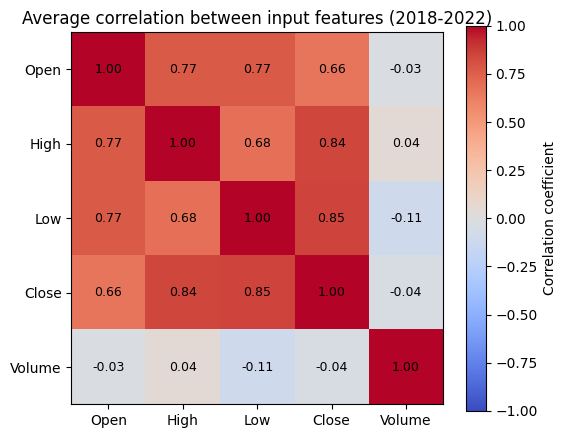

,Pair,Min,Average,Max
0,Open - High,0.71,0.77,0.88
1,Open - Low,0.71,0.77,0.89
2,Open - Close,0.59,0.66,0.81
3,Open - Volume,-0.06,-0.03,0.02
4,High - Low,0.56,0.68,0.84
5,High - Close,0.79,0.84,0.91
6,High - Volume,-0.02,0.04,0.16
7,Low - Close,0.79,0.85,0.91
8,Low - Volume,-0.18,-0.11,-0.05
9,Close - Volume,-0.10,-0.04,0.03


In [ ]:
# Correlation between the five input features ----
# Uses the initial training period only (before 2023), averaged over the six stocks.
# Strongly correlated inputs matter for SHAP (RQ2): the model can rely on either feature,
# so credit may be split between them differently from stock to stock.
feature_corrs = {s: transform_features(df[df.index < "2023-01-01"]).corr() for s, df in cleaned_data.items()}
avg_feature_corr = sum(feature_corrs.values()) / len(feature_corrs)

plt.figure(figsize=(6, 5))
plt.imshow(avg_feature_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation coefficient")
plt.xticks(range(5), avg_feature_corr.columns)
plt.yticks(range(5), avg_feature_corr.index)
for i in range(5):
    for j in range(5):
        plt.text(j, i, f"{avg_feature_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.title("Average correlation between input features (2018-2022)")
plt.show()

# Range across the six stocks for each feature pair
pairs = [(a, b) for i, a in enumerate(avg_feature_corr.columns) for b in avg_feature_corr.columns[i + 1:]]
pd.DataFrame([{"Pair": f"{a} - {b}",
               "Min": min(c.loc[a, b] for c in feature_corrs.values()),
               "Average": avg_feature_corr.loc[a, b],
               "Max": max(c.loc[a, b] for c in feature_corrs.values())} for a, b in pairs]).round(2)

**Feature correlation and SHAP.** Four of the five inputs are strongly correlated: Close with High (0.84) and Low (0.85), and Open with High and Low (0.77). This is expected, because all four are measured against the same previous close: on a day the stock rises, Open, High and Close all tend to be positive. Volume change is almost uncorrelated with the price features (−0.11 to 0.04).

+ **For prediction** this is not a problem; the features simply carry overlapping information.
+ **For SHAP (RQ2)** it matters. When features are correlated, a model can rely on either one, and SHAP may split the credit between them differently for different stocks or folds. Differences in feature rankings between stocks could then reflect this rather than a real difference in behaviour. This should be stated when interpreting the Spearman correlations of SHAP rankings, and one option is to also compare rankings with the four price features grouped together.

### 5.2 The per-fold preprocessing function

For one stock and one fold, `preprocess_fold` does these steps in the following order:

1. **Keep only data up to the end of the test quarter**. For example, AAPL dataset is from 2/1/2018 to 30/12/2025. Fold 1 uses the first quarter of 2023 (1/1/2023-31/3/2023) as the test quarter. The dataset after 31/3 is not included in Fold 1
2. **Split the dataset**: train (first 85% of the pre-test data) - validation (last 15% of the pre-test data) - test (the quarter)
3. **Winsorisation**: In this step, the 1st and 99th percentile thresholds of each feature are calculated using only the training data of the corresponding fold. Values beyond these thresholds in the training, validation and test sets are then replace with the threshold values themselves. This limits the influence of extreme trading days on model training without removing any observations, so the continuity of the time series is preserved. The thresholds are estimated from the training data alone to prevent data leakage: if they were calculated on the full dataset, the model would indirectly gain prior nowledge of the volatility in the test period. Each fold therefore has its own thresholds, which are recalculated as the training window expands by one quarter. The target values of the test set are never clipped, so the models are always evaluated against actual prices.
4. `StandardScaler`: After winsorisation, the features are standardised using StandardScaler, which transforms each feature to a common scale with a mean of 0 and a std of 1, using the formular:
$$
z = \frac{x - \mu}{\sigma}
$$
where $\mu$ is the mean and $\sigma$ is the standard deviation of the feature. This step is necessary because the features differ in magnitude. When all features share a common scale, neural networks train more stably and efficiently.
5. **Build 60-day sequence** To predict day t, the inputs is day t-60 to day t-1.

6. **The test target is never clipped**, so the models are always evaluated against the real prices.

In [182]:
LOOKBACK = 60           # each input - the previous 60 trading days
VAL_FRAC = 0.15       # last 15% of each fold's training data = validation set
WINSOR = (0.01, 0.99)   # clip at the 1st and 99th percentiles 

In [183]:
# the per-fold preprocessing function

def preprocess_fold (df, test_start, test_end, winsor=WINSOR):
    # Step 1: keep data only up to the end of this fold's test quarter
    df = df[df.index <= test_end]
    feats = transform_features(df) # 5 return-based features (from 5.1)
    dates = feats.index
    close = df['Close'].reindex(dates)  # closing prices on the same dates

    # Step 2: split dates into train/validation/test
    pre_test_dates = dates[dates < test_start]      #everything before the test quarter
    val_start = pre_test_dates[int(len(pre_test_dates) * (1 - VAL_FRAC))]   # first validation day (last 15%)
    is_train_row = dates < val_start 

    # Step 3: winsorisation (limits learned from training rows only)
    if winsor is not None:
        low = feats[is_train_row].quantile(winsor[0]) # 1st percentile of each feature
        high = feats[is_train_row].quantile(winsor[1]) # 99th percentile of each feature
        feats_clipped = feats.clip(lower=low, upper=high, axis =1) #clipped the value to the limit
    else:
        feats_clipped = feats.copy() # winsor is none, feats_clipped is a copy of original features

    # Step 4: StandardScaler (fitted on TRAINING rows only)
    scaler = StandardScaler().fit(feats_clipped[is_train_row])
    X_all = scaler.transform(feats_clipped)     # scaled inputs for every day

    # Target = that day's log return
    # Train/validation use te clipped value, the test period uses the REAL (unclipped)
    y_real = feats['Close'].values          # real value
    y_clipped = feats_clipped['Close'].values   # winsorised value
    y_mean = y_clipped[is_train_row].mean()
    y_std = y_clipped[is_train_row].std()

    # Step 5: build 60-day sequences
    X, y, target_dates = [], [], []
    for i in range (LOOKBACK, len(dates)):
        d = dates[i]        # the day we want to predict
        X.append(X_all[i - LOOKBACK:i])     # the 60 days before it
        # Step 6: test targets are never clipped
        target = y_real[i] if d >= test_start else y_clipped[i]
        y.append((target - y_mean)/y_std)
        target_dates.append(d)

    X = np.array(X)
    y = np.array(y)
    target_dates = pd.DatetimeIndex(target_dates)

    # Assign each sequence to train/validation/test by the date it predicts
    train = target_dates < val_start
    val = (target_dates >= val_start) & (target_dates < test_start)
    test = target_dates >= test_start

    return {
        "X_train": X[train], "y_train": y[train],
        "X_val": X[val], "y_val": y[val],
        "X_test": X[test], "y_test": y[test],
        "test_dates": target_dates[test],
        "test_prev_close": close.shift(1)[target_dates[test]].values,    # yesterday's close
        "test_actual": close[target_dates[test]].values,
        "y_mean": y_mean, "y_std": y_std,
        "val_start": val_start,
        # Newly added by Claude: also return the fitted limits and scaler so leakage check 2 can compare them
        "winsor_low": low if winsor is not None else None,
        "winsor_high": high if winsor is not None else None,
        "scaler": scaler
    }

In [184]:
# convert predictions back to prices
def to_price (y_scaled, prev_close, y_mean, y_std):
    # convert a scaled predicted log return back to a closing price
    predicted_return = y_scaled * y_std + y_mean #undo the scaling
    return prev_close * np.exp(predicted_return)

In [185]:
# Use NVIDIA to check
k, start, end = folds[0]
fold = preprocess_fold(cleaned_data['NVDA'], start, end)

print("Validation starts:", fold['val_start'].date())
print("X_train:", fold['X_train'].shape, " -> (samples, 60 days, 5 features)")
print("X_Val: ", fold["X_val"].shape)
print("X_test: ", fold['X_test'].shape)

# Converting the TRUE test targets back must give the TRUE prices
back = to_price(fold['y_test'], fold['test_prev_close'], fold['y_mean'], fold['y_std'])
print("Conversion back to price is exact:", np.allclose(back, fold['test_actual']))

Validation starts: 2022-04-01
X_train: (1009, 60, 5)  -> (samples, 60 days, 5 features)
X_Val:  (189, 60, 5)
X_test:  (62, 60, 5)
Conversion back to price is exact: True


### 5.3 Run the preprocessing for every stock and fold

This section executes the `preprocess_fold` function for all 6 stocks across 12 folds, totaling 72 iterations. The results from each iteration are stored in `all_folds` for use in the subsequent model training phase. For each stock and each fold, the code performs two checks to determine whether the test data falls outside the range learned by the model. The first check, based on price, calculates the proportion of days in the test quarter where the closing price exceeds the highest price observed during the training period. The second check, based on log returns, calculates the proportion of target values ​​in the test set that fall outside the range (minimum to maximum) of the target values ​​in the training set. These results are averaged across the 12 folds and presented in a comparison table. When using price, this proportion is quite high—averaging 39.1% for NVDA, 34.4% for JPM, and 30.6% for CBA. In contrast, when using log returns, the proportion drops to approximately 0.7–2.0% for all stocks. This indicates that shifting the target from price to log returns ensures the model rarely needs to extrapolate beyond the range of the data it has already learned.

In [186]:
# Run the preprocessing for every stock and every fold
all_folds = {}   # keeps every fold's data for the modelling phase, e.g. all_folds[('NVDA', 1)]
rows = []        # one row per stock and fold

for name in stock:
    for k, start, end in folds:
        # Preprocess this stock for this fold
        fold = preprocess_fold(cleaned_data[name], start, end)
        all_folds[(name, k)] = fold

        # RETURNS: % of test targets outside the range seen in training
        low  = fold['y_train'].min()
        high = fold['y_train'].max()
        outside = (fold['y_test'] < low) | (fold['y_test'] > high)

        # PRICES (same check as section 3.2): % of test days above the highest training price
        close = cleaned_data[name]['Close']
        train_max  = close[close.index < start].max()
        test_close = close[(close.index >= start) & (close.index <= end)]
        above_max  = test_close > train_max

        rows.append({'Stock': name,
                     'Fold': k,
                     'Prices: % test days above training max':         above_max.mean() * 100,
                     'Returns: % test targets outside training range': outside.mean() * 100})

summary = pd.DataFrame(rows)

# Compare prices vs returns, averaged over the 12 folds
comparison = (summary.groupby('Stock')[['Prices: % test days above training max',
                                        'Returns: % test targets outside training range']]
                     .mean()
                     .round(1)
                     .reindex(stock))     # keep the original stock order
comparison

,Prices: % test days above training max,Returns: % test targets outside training range
Stock,,
AAPL,22.5,0.8
NVDA,39.1,2.0
JPM,34.4,1.1
BHP,3.3,0.7
CBA,30.6,0.8
GMG,13.0,1.9


### 5.4 ARIMA Input: Selecting the Differencing Order (d) for each fold

Unlike LSTM and CNN-LSTM, ARIMA does not require data normalization, winsorization, or the use of 60-day rolling windows. This model operates directly on the log-transformed closing prices. However, ARIMA requires the data series to be stationary. Therefore, it is necessary to determine the parameter $d$—the number of times the series must be differenced to achieve stationarity. In this step, the Augmented Dickey-Fuller (ADF) test is applied to the training data for each fold, which includes only the periods prior to the test quarter, ensuring that no future information is leaked. The procedure is as follows: if the ADF $p$-value is less than 0.05, the series is considered stationary, and the current value of $d$ is maintained. Otherwise, the series is differenced once more, and the test is repeated. The results indicate that $d = 1$ in all 72 cases (6 stocks × 12 folds). This implies that the log-transformed prices are non-stationary, but they become stationary after a single round of differencing. A first-order difference of log prices is equivalent to the log return. This finding is consistent with the ADF test results from the Exploratory Data Analysis (EDA) section (4.3) and further demonstrates that both ARIMA and the deep learning models are, in essence, predicting the same quantity: the daily log return.

In [187]:
def choose_d(series, max_d=2):
    """Return the smallest number of differences that makes the series stationary (ADF p < 0.05)."""
    for d in range(max_d + 1):
        p_value = adfuller(series)[1]     # ADF test, [1] is the p-value
        if p_value < 0.05:                # p < 0.05: reject "non-stationary", so the series is stationary
            return d
        series = np.diff(series)          # not stationary yet: take one more difference and test again
    return max_d

d_table = {}
for name in stock:
    d_values = []
    for k, start, end in folds:
        # TRAINING data only: closing prices before the test quarter starts
        train_close = cleaned_data[name].loc[cleaned_data[name].index < start, 'Close']
        log_price = np.log(train_close).values          # ARIMA works on the log price
        d_values.append(choose_d(log_price))
    d_table[name] = d_values

# Table: rows = stocks, columns = folds
d_table = pd.DataFrame(d_table, index=[f'Fold {k}' for k, _, _ in folds]).T
d_table

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Fold 6,Fold 7,Fold 8,Fold 9,Fold 10,Fold 11,Fold 12
AAPL,1,1,1,1,1,1,1,1,1,1,1,1
NVDA,1,1,1,1,1,1,1,1,1,1,1,1
JPM,1,1,1,1,1,1,1,1,1,1,1,1
BHP,1,1,1,1,1,1,1,1,1,1,1,1
CBA,1,1,1,1,1,1,1,1,1,1,1,1
GMG,1,1,1,1,1,1,1,1,1,1,1,1


**Note on the fairness of the comparison.** ARIMA and the deep-learning models do not receive identical inputs: ARIMA uses only the raw (unwinsorised) log closing price, while LSTM and CNN-LSTM use five winsorised, standardised return features. All models are evaluated on the same test days against the same unclipped closing prices, so the error metrics are directly comparable. However, a performance difference reflects the whole approach (model + inputs + preprocessing), not the model architecture alone. This should be stated when answering RQ1.

### 5.5 Naive baseline (tomorrow's price = today's price)

The part is to define the naive baseline. It assumes that tomorrow’s closing price will be identical to today’s closing price. This method requires no training and involves no parameters. Nevertheless, it often yields a relatively low error rate, as stock prices typically change very little from one day to the next. For this reason, the naive baseline serves as a minimum benchmark for evaluating models such as ARIMA, LSTM, and CNN-LSTM. Without this point of comparison, it would be impossible to determine whether an error rate is considered good or poor. A model is only truly valuable if its error rate is lower than that of the naive baseline; if the error is equal to or higher, the model has failed to learn any useful information and is merely “repeating yesterday’s price.” This phenomenon explains why many predicted trajectories appear to align closely with actual prices while, in reality, they are simply lagged by one day. The naive baseline is calculated for each stock across all 12 folds, using the same metrics—RMSE, MAE, and MAPE—as those applied to the primary models.

In [188]:
naive = []
for name, df in cleaned_data.items():
    for k, start, end in folds:
        test = (df.index >= start) & (df.index <= end)
        actual = df["Close"][test]
        predicted = df["Close"].shift(1)[test]              # yesterday's close
        error = actual - predicted
        naive.append({"Stock": name, "Fold": k,
                      "RMSE": np.sqrt((error ** 2).mean()),
                      "MAE": error.abs().mean(),
                      "MAPE (%)": 100 * (error.abs() / actual).mean()})
naive = pd.DataFrame(naive)
naive.head()

# mean ± std over the 12 folds
naive_summary = naive.groupby("Stock")[["RMSE", "MAE", "MAPE (%)"]].agg(["mean", "std"]).round(3)
naive_summary

RMSE           MAE        MAPE (%)       
        mean    std   mean    std     mean    std
Stock                                            
AAPL   3.065  1.163  2.223  0.672    1.103  0.312
BHP    0.584  0.076  0.451  0.056    1.054  0.150
CBA    1.633  0.621  1.226  0.445    0.903  0.151
GMG    0.464  0.146  0.342  0.101    1.176  0.156
JPM    2.957  1.246  2.110  0.824    1.002  0.217
NVDA   2.882  1.597  2.178  1.234    2.257  0.565

### 5.6 Data Leakage check

Data leakage occurs when a model inadvertently “sees” information from the future during the training or prediction process. This leads to artificially high performance on the test set, results that the model cannot replicate when deployed in a real-world scenario. Such errors are notoriously difficult to detect by eye, as the code executes without throwing any exceptions. This section verifies that the preprocessing pipeline is free from data leakage. The approach is as follows: intentionally “corrupt” the future data by multiplying all values ​​occurring after the 30th day of the test quarter by a factor of three. Then, re-run the entire preprocessing pipeline and compare the output against the original results. If the pipeline is implemented correctly, components derived solely from historical data should remain unchanged. These components include the training and validation sets, winsorization thresholds, scalers, and the first 30 input sequences of the test set. If any of these elements change, it indicates that information from the future has leaked into the past. This validation step is particularly crucial here, given the use of walk-forward validation, winsorization, and fold-specific normalization—processes where it is easy to accidentally incorporate test data. This check provides concrete evidence that the model’s subsequent performance evaluation is honest and reliable.

In [189]:
# Corrupt all prices AFTER the 31st test day, preprocess again, and check that
# nothing that should only use past data has changed.

k, start, end = folds[4]          # use fold 5 as an example

for name, df in cleaned_data.items():
    # Trading days in this fold's test quarter
    test_days = df.index[(df.index >= start) & (df.index <= end)]

    # Corrupt the future: multiply every price and volume after the 31st test day by 3
    corrupted = df.copy()
    corrupted.loc[corrupted.index > test_days[30], ["Open", "High", "Low", "Close", "Volume"]] *= 3

    # Preprocess the original data and the corrupted data
    a = preprocess_fold(df, start, end)
    b = preprocess_fold(corrupted, start, end)

    # Check 1: everything built from past data must be exactly the same
    #   - training inputs and targets
    #   - validation inputs and targets
    #   - the first 31 test inputs (their 60-day windows end before the corrupted days)
    same = (np.allclose(a["X_train"], b["X_train"]) and np.allclose(a["y_train"], b["y_train"]) and
            np.allclose(a["X_val"],   b["X_val"])   and np.allclose(a["y_val"],   b["y_val"])   and
            np.allclose(a["X_test"][:31], b["X_test"][:31]))

    # Check 2: the later test inputs MUST change (proves the corruption actually happened)
    changed = not np.allclose(a["X_test"][31:], b["X_test"][31:])

    print(f"{name}: no leakage = {same}, later test inputs changed = {changed}")

AAPL: no leakage = True, later test inputs changed = True
NVDA: no leakage = True, later test inputs changed = True
JPM: no leakage = True, later test inputs changed = True
BHP: no leakage = True, later test inputs changed = True
CBA: no leakage = True, later test inputs changed = True
GMG: no leakage = True, later test inputs changed = True


**Leakage check 2: corrupt the validation period.** The check above only changes test-period data. This second check multiplies every price and volume in the **validation** period by 3 and compares the winsorisation limits and the scaler directly. Because both must be learned from training rows only, they and the training sequences must stay exactly the same, while the validation inputs must change.

In [191]:
# ---- leakage check 2 - corrupt the VALIDATION period ----
# The winsorisation limits and the scaler must be learned from TRAINING rows only.
# So changing the validation data must leave them, and the training sequences, unchanged.
k, start, end = folds[4]          # fold 5, same as above

for name, df in cleaned_data.items():
    a = preprocess_fold(df, start, end)

    # Multiply every price and volume in the validation period by 3
    corrupted = df.copy()
    is_val = (corrupted.index >= a["val_start"]) & (corrupted.index < start)
    corrupted.loc[is_val, ["Open", "High", "Low", "Close", "Volume"]] *= 3
    b = preprocess_fold(corrupted, start, end)

    same_limits = (np.allclose(a["winsor_low"], b["winsor_low"]) and
                   np.allclose(a["winsor_high"], b["winsor_high"]))
    same_scaler = (np.allclose(a["scaler"].mean_, b["scaler"].mean_) and
                   np.allclose(a["scaler"].scale_, b["scaler"].scale_))
    same_train = np.allclose(a["X_train"], b["X_train"]) and np.allclose(a["y_train"], b["y_train"])
    val_changed = not np.allclose(a["X_val"], b["X_val"])   # proves the corruption happened

    print(f"{name}: limits unchanged = {same_limits}, scaler unchanged = {same_scaler}, "
          f"training data unchanged = {same_train}, validation changed = {val_changed}")

AAPL: limits unchanged = True, scaler unchanged = True, training data unchanged = True, validation changed = True
NVDA: limits unchanged = True, scaler unchanged = True, training data unchanged = True, validation changed = True
JPM: limits unchanged = True, scaler unchanged = True, training data unchanged = True, validation changed = True
BHP: limits unchanged = True, scaler unchanged = True, training data unchanged = True, validation changed = True
CBA: limits unchanged = True, scaler unchanged = True, training data unchanged = True, validation changed = True
GMG: limits unchanged = True, scaler unchanged = True, training data unchanged = True, validation changed = True


All six stocks pass: the winsorisation limits, the scaler and the training data are identical after the validation period is corrupted, and the validation inputs did change. Together with the first check, this confirms that nothing from the validation or test periods is used to fit the preprocessing.